# Machine Learning — Homework 2: Classification and Evaluation Metrics

**Course:** Machine Learning — National University of Kyiv-Mohyla Academy (NaUKMA)
**Instructor:** Dmytro Kuzmenko (kuzmenko@ukma.edu.ua)
**Module:** Week 3 — *"Learning a Boundary (Classification)"*

## Meta

- **Points:** 5 (Homework 2 of 6; homeworks total 30% of the final grade)
- **Estimated time:** 2.5–3.5 hours
- **Prerequisites:** Weeks 1–3. Python, `numpy`, `matplotlib`, `scikit-learn` (logistic regression, k-NN, confusion matrix, precision/recall/F1).
- **Deadline:** [to be announced by the instructor]
- **Submission:** one executed `.ipynb` file with the AI Use Disclosure completed.
- **Late policy:** 5 free late days across all homeworks; 1 late day = up to 24 h; after that, −25% of the maximum per additional 24 h.

## AI Use Disclosure

Policy: AI tools are allowed for homeworks, but you must disclose their use and remain responsible for every claim in your submission. On the midterm and final, AI and external help are forbidden.

- **AI tools used:** ... Gemini
- **Nature of assistance:** ... використав для пояснення теорії та складних момпнтів (зокрема, чому PR-крива змінюється при зміні превалентності, а ROC — ні, та як масштабування впливає на k-NN), а також для допомоги у формулюванні та стилістичному редагуванні відповідей
- **Representative prompts or relevant interaction:** ... «Поясни, чому PR-крива суттєво зміщується, а ROC-крива майже не змінюється при падінні превалентності позитивного класу до 2%?»
«Як параметр k у k-NN впливає на складність моделі, і чому масштабування ознак важливе для відстаней, але не для дерев рішень?»
- **What I independently verified or changed:** ... Самостійно перевірив усі числові метрики за результатами виконання коду та графіками (ROC-AUC 0.935 / 0.936, AP 0.873 / 0.807, Accuracy та F1 для різних k, а також ріст F1 з 0.850 до 0.900 після StandardScaler). Проаналізував побудовані графіки межі прийняття рішень для k=1 та k=31 для визначення зон перенавчання й недонавчання.   Переконався, що всі підсумкові висновки (наприклад, вибір k=11) повністю відповідають згенерованим у графіках і таблицях даним.

## Learning Objectives

- Train logistic regression and k-NN on an imbalanced two-class problem and report a coherent metric set.
- Choose an operating threshold from a precision–recall trade-off given an explicit cost scenario.
- Interpret ROC and PR curves and explain how prevalence reshapes them.
- Select k for k-NN and verify the role of feature scaling.

# Warm-up

We generate a synthetic imbalanced two-class problem: 1000 points, 2 features, about 10% positives, mild label noise, fixed seed. The splits are *stratified*, so the prevalence stays close to 10% in the training, validation, and test sets.

Prevalence (share of positives) — train: 0.108, validation: 0.110, test: 0.110


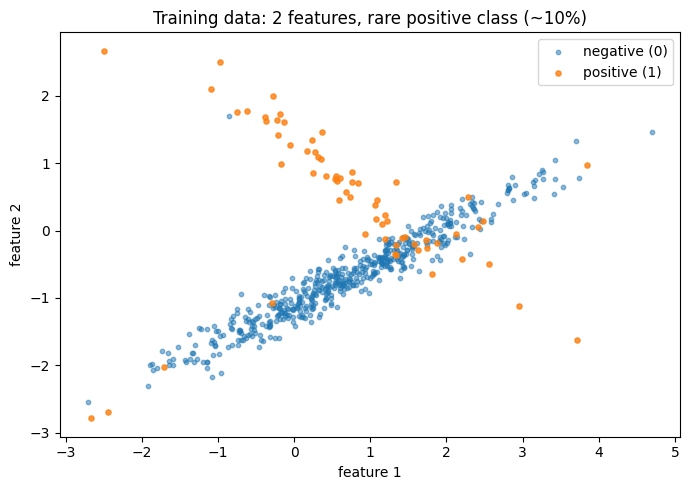

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,
                             accuracy_score, precision_score, recall_score,
                             f1_score, roc_curve, roc_auc_score,
                             precision_recall_curve, average_precision_score)

X, y = make_classification(
    n_samples=1000, n_features=2, n_informative=2, n_redundant=0,
    n_clusters_per_class=1, flip_y=0.02, class_sep=0.7,
    weights=[0.9, 0.1], random_state=42,
)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.25, random_state=42, stratify=y_train)

print("Prevalence (share of positives) — train: {:.3f}, validation: {:.3f}, test: {:.3f}".format(
    y_train.mean(), y_val.mean(), y_test.mean()))

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(X_train[y_train == 0, 0], X_train[y_train == 0, 1], s=10, alpha=0.5, label="negative (0)")
ax.scatter(X_train[y_train == 1, 0], X_train[y_train == 1, 1], s=14, alpha=0.8, label="positive (1)")
ax.set_xlabel("feature 1")
ax.set_ylabel("feature 2")
ax.set_title("Training data: 2 features, rare positive class (~10%)")
ax.legend()
plt.tight_layout()
plt.show()

# Guided Exercise

## Task 1: Baseline and core metrics

Train logistic regression and k-NN (k = 5) on the same training split. For each model, show the confusion matrix on the test set and report accuracy, precision, recall, specificity, and F1. Also compute the accuracy of the trivial majority-class baseline.

**Experiment (A).** Fit both models and compute the metric table:

In [2]:
def metric_table(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "specificity": tn / (tn + fp) if (tn + fp) > 0 else np.nan,
        "F1": f1_score(y_true, y_pred, zero_division=0),
    }

lr = LogisticRegression(max_iter=2000, random_state=42).fit(X_train, y_train)
knn5 = KNeighborsClassifier(n_neighbors=5).fit(X_train, y_train)

rows = []
for name, model in [("Logistic regression", lr), ("k-NN (k=5)", knn5)]:
    y_pred = model.predict(X_test)
    rows.append({"model": name, **metric_table(y_test, y_pred)})

df_metrics = pd.DataFrame(rows)
df_metrics

majority_acc = max(y_test.mean(), 1 - y_test.mean())
print(f"Majority-class baseline accuracy on test: {majority_acc:.3f}")

Majority-class baseline accuracy on test: 0.890


**Evidence (C).** Confusion matrices for both models:

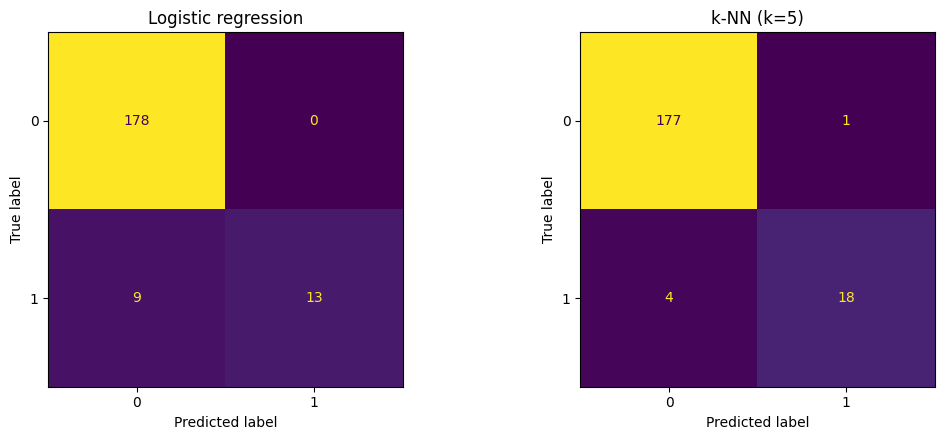

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (name, model) in zip(axes, [("Logistic regression", lr), ("k-NN (k=5)", knn5)]):
    ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

**Interpretation (D).** The positive class is about 10% of the test set. Why is accuracy a misleading headline metric here? Compare the two models: which metric differs most, and what does that difference mean for a screening use case where we must not miss positives?

**Your answer:**  Чому Accuracy є оманливою метрикою: у нас дуже несбалансовані дані: 90% це клас 0 і лише 10% це клас 1. Якщо створити найпростішу модель, що завжди буде казати 0, вона матиме Accuracy = 89% (бо вгадає більшість даних).Але при цьому вона не знайде жодного позитивного об'єкта. Тому Accuracy тут створює лише ілюзію, що все працює добре, хоча насправді вона не показує, чи вміє модель шукати клас 1.

Яка метрика найбільше відрізняється між моделями: якщо подивитися на матриці помилок: Logistic Regression правильно знайшла 13 позитивних і пропустила 9 (Recall = 13/22 приблизно 59.1%).   k-NN (k=5) знайшла 18 позитивних і пропустила 4 (Recall = 18/22 і це близько 81.8%).   Найбільше відрізняється Recall (повнота). У k-NN вона відчутно вища — 81.8\% проти 59.1\%.

Що ця різниця означає для завдання скринінгу: у скринінгу (наприклад, у медицині або пошуку шахраїв) найгірше, що ми можемо зробити — це пропустити хворобу/позитивний випадок (помилка False Negative). Логістична регресія пропустила аж 9 із 22 хворих/позитивних (майже 40\%).   k-NN пропустив лише 4 з 22, але знайшов 81.8\% усіх випадків, отримавши при цьому лише 1 хибний виклик (FP = 1). Висновок: для скринінгу k-NN краща, бо завдяки високому Recall вона пропускає мінімум важливих випадків.

**Decision (B).** If you had to report exactly one metric to a non-technical stakeholder, which one would you choose and why? Would the choice differ for a general-purpose classifier on balanced data?

**Your answer:** Яку одну метрику обрати для нетехнічного замовника: я б обрав F1-score, бо людині без технічного бэкграунду важко стежити за двома метриками одночасно. F1-score об'єднує їх в один зрозумілий показник (від 0 до 1 або від 0% до 100%), який відображає баланс між точністю та повнотою. На відміну від Accuracy, F1-score не введе замовника в оману красивими 89%, якщо модель просто ігноруватиме рідкісний позитивний клас. Проте якщо специфіка бізнесу вимагає мінімізувати пропуски (наприклад, у медицині), можна обрати Recall, щоб взагалі нічого не пропустити.
Чи змінився б вибір для звичайного класифікатора на збалансованих даних: так, змінився б. На збалансованих даних (коли класів у вибірці приблизно 50/50) я б обрав Accuracy. Коли класи збалансовані, Accuracy стає повністю адекватною, інтуїтивною та найпростішою метрикою. Замовникам дуже легко зрозуміти: «Наша модель дає правильну відповідь у 92% випадків». Перевантажувати звіт складнішими метриками по типу F1-score для нетехнічної аудиторії вже немає потреби.

**Counterfactual (E).** If the dataset were perfectly balanced (50/50), how would the relationship between accuracy and F1 change? Which of the two models would you expect to win, and why?

**Your answer:**  Як зміниться зв'язок між Accuracy та F1 на збалансованих даних (50/50): вони стануть практично однаковими: коли класи збалансовані, хибнопозитивні та хибнонегативні помилки мають однакову вагу. У такій ситуації Accuracy та F1-score рухаються синхронно: якщо зростає Accuracy, пропорційно зростає й F1. Accuracy втрачає свою оманливість: На відміну від випадку з дисбалансом, тут тривіальна модель матиме Accuracy лише 50% (випадкове вгадування). Тому висока Accuracy справді свідчитиме про реальну якісну роботу моделі.
Яка з двох моделей переможе і чому: переможе k-NN (k=5) (або покаже мінімум не гірший, а швидше за все кращий результат). Логістична регресія є лінійною моделлю — вона може провести лише пряму лінійну розділювальну межу. k-NN є нелінійною моделлю: вона будує гнучкі, нелінійні межі прийняття рішень на основі сусідніх точок.

## Task 2: Operating threshold under asymmetric costs

Cost scenario: we screen for a rare condition. Missing a positive (a false negative) is 10 times more expensive than a false alarm (a false positive). Logistic regression outputs probabilities, and the decision threshold is a free parameter. Sweep the threshold and choose the operating point.

**Experiment (A).** Sweep the decision threshold on the validation probabilities and record precision, recall, F1, and expected cost (cost = FP + 10 × FN):

In [4]:
proba_val = lr.predict_proba(X_val)[:, 1]
thresholds = np.linspace(0.05, 0.95, 19)

rows = []
for t in thresholds:
    y_pred = (proba_val >= t).astype(int)
    m = metric_table(y_val, y_pred)
    tn, fp, fn, tp = confusion_matrix(y_val, y_pred).ravel()
    rows.append({"threshold": t, "precision": m["precision"], "recall": m["recall"],
                 "F1": m["F1"], "cost": fp + 10 * fn})
df_threshold = pd.DataFrame(rows)
df_threshold

,threshold,precision,recall,F1,cost
0,0.05,0.175000,0.954545,0.295775,109
1,0.10,0.377358,0.909091,0.533333,53
2,0.15,0.655172,0.863636,0.745098,40
3,0.20,0.750000,0.681818,0.714286,75
4,0.25,0.933333,0.636364,0.756757,81
5,0.30,0.933333,0.636364,0.756757,81
6,0.35,0.928571,0.590909,0.722222,91
7,0.40,0.928571,0.590909,0.722222,91
8,0.45,1.000000,0.590909,0.742857,90
9,0.50,1.000000,0.545455,0.705882,100


**Evidence (C).** Plot the trade-off curves and the cost curve:

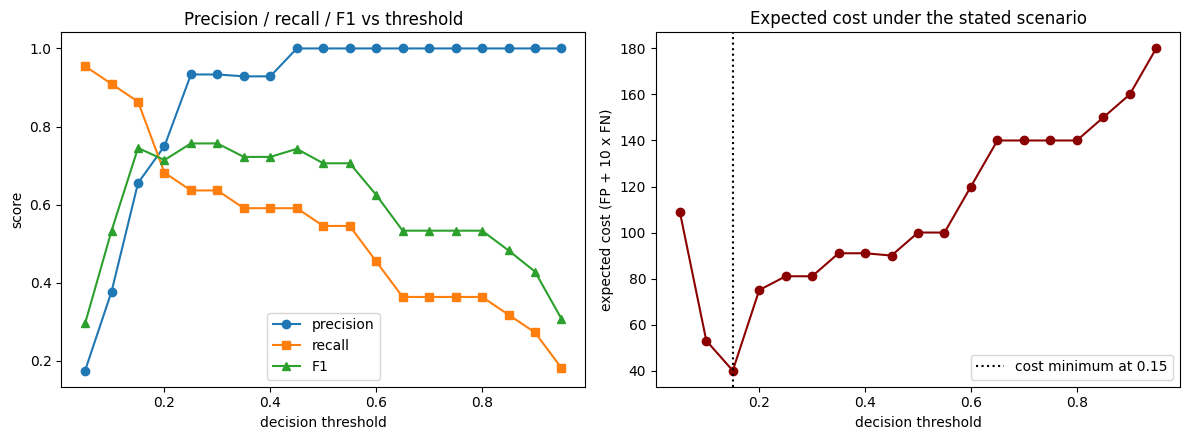

Lowest expected cost: 40 at threshold 0.15


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ax = axes[0]
ax.plot(df_threshold["threshold"], df_threshold["precision"], "o-", label="precision")
ax.plot(df_threshold["threshold"], df_threshold["recall"], "s-", label="recall")
ax.plot(df_threshold["threshold"], df_threshold["F1"], "^-", label="F1")
ax.set_xlabel("decision threshold")
ax.set_ylabel("score")
ax.set_title("Precision / recall / F1 vs threshold")
ax.legend()
ax = axes[1]
ax.plot(df_threshold["threshold"], df_threshold["cost"], "o-", color="darkred")
best_t = df_threshold.loc[df_threshold["cost"].idxmin(), "threshold"]
ax.axvline(best_t, color="k", ls=":", label=f"cost minimum at {best_t:.2f}")
ax.set_xlabel("decision threshold")
ax.set_ylabel("expected cost (FP + 10 x FN)")
ax.set_title("Expected cost under the stated scenario")
ax.legend()
plt.tight_layout()
plt.show()

print(f"Lowest expected cost: {df_threshold['cost'].min():.0f} at threshold {best_t:.2f}")

**Decision (B).** Choose the operating threshold for the stated cost scenario and justify it with the numbers in the table or plots. Explain in one sentence what this threshold means operationally (what share of positives will be missed).

**Your answer:** Вибір порогу прийняття рішень та його обґрунтування: оптимальним порогом класифікації є 0.15. Мінімальні витрати саме при порозі 0.15 функція очікуваних витрат досягає свого абсолютного мінімуму і становить 40. Висока повнота: при порозі 0.15 повнота становить 0.8636 (86.36%), що є суттєво вищим значенням порівняно з 0.5455 (54.55%) при порозі 0.50. Оскільки ціна пропуску позитивного об'єкта (FN) у 10 разів вища за хибну тривогу (FP), зміщення порогу вбік менших значень дозволяє значно зменшити кількість дорогих помилок FN. Прийнятна точність: при порозі 0.15 точність залишається на високому рівні 0.6552 (65.52%), а показник F1-score досягає одного з найвищих значень у таблиці — 0.7451.
Операційний зміст порогу: операційно поріг 0.15 означає, що ми відносимо об'єкт до позитивного класу, якщо модель оцінює його ймовірність хоча б у 15%, при цьому ми пропускаємо лише 13.64% позитивних випадків (оскільки Recall = 86.36%, то пропущені 1 - 0.8636 = 0.1364).

**Interpretation (D).** Explain the shapes of the curves: why does precision drop sharply at very low thresholds, and why does recall collapse at high thresholds? Where is F1 maximized, and why is that not necessarily the best operating point in this scenario?

**Your answer:** Чому Precision різко падає при дуже низьких порогах: при дуже низькому порозі (наприклад, t = 0.05) модель стає занадто підозрілою і класифікує майже всі об'єкти як позитивні. Через це у нас з'являється величезна кількість хибнопозитивних спрацювань — модель піднімає тривогу щодо об'єктів, які насправді є негативними. Формула точності: Precision = TP/(TP+FP) . Оскільки знаменник (FP) різко зростає, значення Precision падає майже до нуля (у нашому випадку до 0.175).
Чому Recall обвалюється при високих порогах: при дуже високому порозі (наприклад, t > 0.80) модель стає занадто обережною і відносить об'єкт до класу 1 тільки тоді, коли вона на 100% у цьому впевнена. Більшість реальних позитивних об'єктів не отримують настільки високої ймовірності й класифікуються як негативні, утворюючи велику кількість хибнонегативних помилок. Формула повноти: Recall = TP/(TP+FN). Оскільки чисельник (TP) зменшується, а знаменник зростає через FN, Recall падає до критичних значень (у нашому випадку до 0.182 при t=0.95).
 Де F1 досягає максимуму і чому це не найкращий операційний пункт для нашого сценарію: за таблицею показник F1 досягає свого максимуму (0.7568) при порозі 0.25 або 0.30. Чому це не найкращий вибір:F1-score надає однакову вагу точності та повноті — це середнє гармонійне між ними. Проте за умовами нашого сценарію помилки мають асиметричну вартість: пропустити позитивний випадок у 10 разів дорожче, ніж підняти хибну тривогу. При порозі 0.25 ми маємо F1 = 0.7568, але витрати складають 81. А при порозі 0.15 ми навмисно жертвуємо частиною F1 (0.7451), але отримуємо набагато вищий Recall (86.36\% проти 63.64\%) і мінімізуємо загальні сумарні витрати до 40.

**Counterfactual (E).** If the cost ratio were 1:1 instead of 10:1, would the operating point move up or down? If the classifier were much stronger (AUC ≈ 0.99), how would the precision–recall trade-off curve change?

**Your answer:** Як зміниться поріг, якщо співвідношення витрат стане 1:1 замість 10:1: операційний поріг зсунеться вгору (збільшиться від 0.15 до приблизно 0.25–0.30 або 0.50). Коли співвідношення витрат стане 1:1, хибнонегативна помилка більше не буде в 10 разів дорожчою за хибнопозитивну. Обидві помилки матимуть однакову ціну. У такому випадку мінімізація загальних витрат стає еквівалентною максимізації показника F1-score (або балансу між Precision та Recall). Як видно з нашої попередньої таблиці та графіків, максимум F1 досягається при порозі 0.25–0.30, тому оптимальна точка зсунеться вгору в бік більш суворого (вищого) порогу.
Як зміниться крива Precision–Recall, якщо класифікатор стане набагато сильнішим (AUC ≈ 0.99): крива Precision–Recall випрямиться й зсунеться у право-верхній кут (до точки (1.0, 1.0)). При високій роздільній здатності моделі (AUC ≈ 0.99) ймовірності, які вона видає для об'єктів класу 0 та класу 1, майже повністю розділені. Це означає, що компроміс між точністю та повнотою практично зникає: модель зможе досягати дуже високого Recall (понад 90–95%), взагалі не жертвуючи Precision (тобто майже без хибних тривог).Графік Precision–Recall на більшості діапазонів значень буде майже пласким і перебуватиме біля позначки 1.0, падаючи лише при екстремально високих порогах.

# Discussion Questions

Answer both questions briefly (2–4 sentences each).

**Question 1.** The validation set is used to pick the threshold. Is it legitimate to report metrics computed on the same validation set afterwards? What would you report instead?

**Your answer:** Ні, звітувати підсумкові метрики на тій самій валідаційній вибірці, за якою обирався поріг, не зовсім коректно, оскільки це призводить до перенавчання порогу під валідаційні дані. Замість цього підсумкові метрики та оцінку витрат потрібно обчислювати й звітувати на незалежній тестовій вибірці, використовуючи поріг, знайдений на валідації. Це дасть чесну оцінку того, як модель працюватиме на нових, раніше не бачених даних.

**Question 2.** k-NN and logistic regression achieve similar accuracy here, yet their precision/recall profiles differ. What property of the two models explains this?

**Your answer:** Різниця у профілях Precision/Recall пояснюється типом межі прийняття рішень та способом оцінки ймовірностей. Логістична регресія є лінійною моделлю із гладкою гіперплощиною, яка через дисбаланс класів за умовчанням (поріг 0.5) зміщує межу і відносить сумнівні точки до переважаючого класу. Натомість k-NN (k=5) є нелінійним локальним алгоритмом, який приймає рішення на основі 5 найближчих сусідів, що дозволяє йому краще захоплювати локальні згущення рідкісного позитивного класу і давати вищий Recall без зміни порогу.

# Challenge

## Task 3: ROC and PR curves, and a prevalence change

Plot the ROC and precision–recall curves of logistic regression on the test set and read off AUC and average precision (AP). Then simulate a deployment population with 2% prevalence and see which curve changes and which does not.

**Experiment (A).** Compute and plot both curves on the original test set:

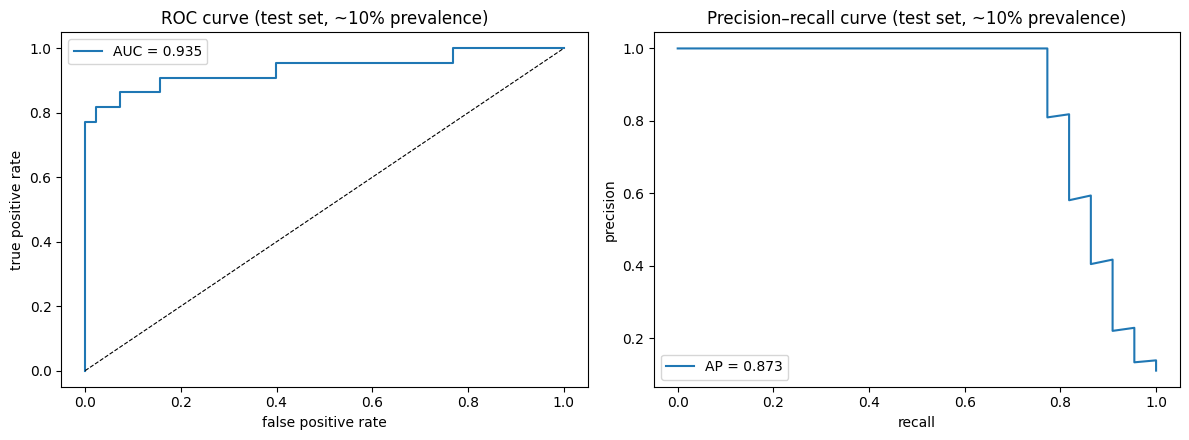

In [6]:
proba_test = lr.predict_proba(X_test)[:, 1]
fpr, tpr, _ = roc_curve(y_test, proba_test)
prec, rec, _ = precision_recall_curve(y_test, proba_test)
auc_score = roc_auc_score(y_test, proba_test)
ap_score = average_precision_score(y_test, proba_test)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ax = axes[0]
ax.plot(fpr, tpr, label=f"AUC = {auc_score:.3f}")
ax.plot([0, 1], [0, 1], "k--", lw=0.8)
ax.set_xlabel("false positive rate")
ax.set_ylabel("true positive rate")
ax.set_title("ROC curve (test set, ~10% prevalence)")
ax.legend()
ax = axes[1]
ax.plot(rec, prec, label=f"AP = {ap_score:.3f}")
ax.set_xlabel("recall")
ax.set_ylabel("precision")
ax.set_title("Precision–recall curve (test set, ~10% prevalence)")
ax.legend()
plt.tight_layout()
plt.show()

**Interpretation (D).** Interpret both curves and the two scalar summaries. What does AUC actually measure, and why is it insensitive to class balance? What does the PR curve emphasize that ROC does not?

**Your answer:**  Інтерпретація обох кривих та двох узагальнюючих метрик ROC-крива та AUC (AUC = 0.935): ROC-крива показує співвідношення між часткою знайдених позитивних об'єктів (TPR = Recall) та часткою хибних тривог серед усіх справжніх негативних об'єктів (FPR). Значення AUC = 0.935 свідчить про високу здатність моделі ранжувати об'єкти (модель чудово відокремлює позитивні випадки від негативних). PR-крива (Precision–Recall) та AP (AP = 0.873):   PR-крива показує залежність точності від повноти. Значення AP = 0.873 відображає середню точність моделі за всіх можливих порогів. Вона залишається високою при малих значеннях Recall, але починає падати, коли ми намагаємося охопити понад 80\% усіх позитивних об'єктів.
Що насправді вимірює AUC і чому вона нечутлива до дисбалансу класів: ймовірнісний зміст AUC полягає у наступному: якщо ми випадково візьмемо один позитивний об'єкт і один негативний, AUC — це ймовірність того, що модель дасть вищу оцінку (імовірність) позитивному об'єкту, ніж негативному. Чому AUC нечутлива до дисбалансу: ROC-крива використовує дві метрики: TPR =TP/(TP +FN) та FPR = FP/(FP + TN). TPR вимірюється виключно відносно позитивного класу (TP + FN). FPR вимірюється виключно відносно негативного класу (FP + TN).   Оскільки обидві метрики нормуються кожна на свій клас окремо, зміна співвідношення між класами (наприклад, якщо ми збільшимо кількість негативних точок у 10 разів) не змінює самі значення TPR та FPR. Тому ROC-крива та AUC залишаються незмінними при зміні дисбалансу.
Що підкреслює PR-крива, чого не робить ROC-крива: PR-крива підкреслює реальну точність при роботі з рідкісним класом. У формулі Precision = TP/(TP + FP) знаменник об'єднує і справжні позитивні передбачення, і хибні тривоги. Якщо негативного класу дуже багато, навіть незначний відсоток помилок дає величезну абсолютну кількість хибних тривог. ROC-крива цього не помічає, бо великий знаменник TN} у FPR приховує зростання FP. Натомість PR-крива одразу реагує: як тільки з'являються хибні тривоги, Precision різко падає. Тому PR-крива набагато краще показує, наскільки надійними є позитивні сигнали моделі в умовах сильного дисбалансу.

**Counterfactual (E).** Simulate the deployment population: keep all test positives and resample negatives (with replacement) so the prevalence becomes 2%. Recompute both curves and compare:

Simulated test set: n = 1100, prevalence = 0.020


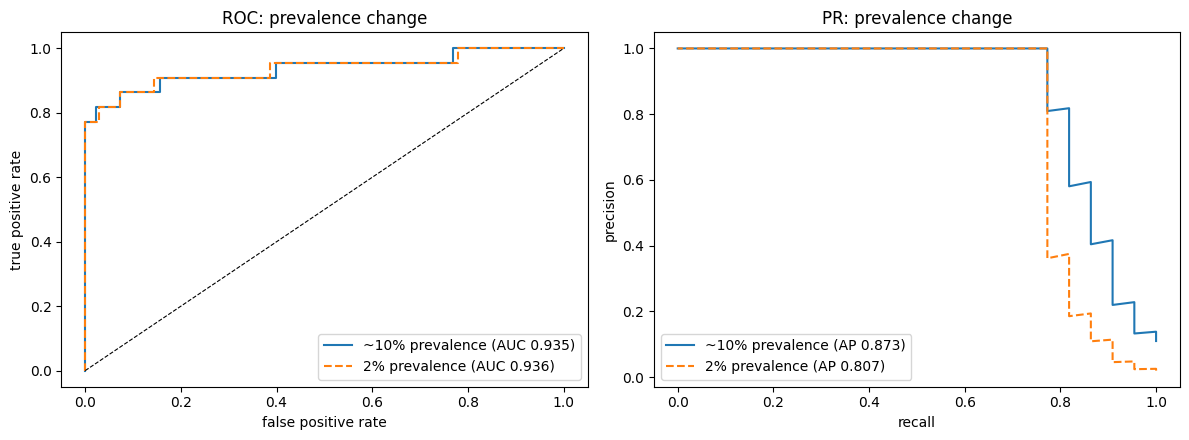

In [7]:
rng = np.random.RandomState(0)
pos_idx = np.where(y_test == 1)[0]
neg_idx_all = np.where(y_test == 0)[0]
n_pos = len(pos_idx)
n_neg_target = int(n_pos * 0.98 / 0.02)
neg_idx = rng.choice(neg_idx_all, size=n_neg_target, replace=True)
X_test_low = np.vstack([X_test[pos_idx], X_test[neg_idx]])
y_test_low = np.hstack([np.ones(n_pos), np.zeros(n_neg_target)])
print(f"Simulated test set: n = {len(y_test_low)}, prevalence = {y_test_low.mean():.3f}")

proba_low = lr.predict_proba(X_test_low)[:, 1]
fpr_low, tpr_low, _ = roc_curve(y_test_low, proba_low)
prec_low, rec_low, _ = precision_recall_curve(y_test_low, proba_low)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(fpr, tpr, label=f"~10% prevalence (AUC {auc_score:.3f})")
axes[0].plot(fpr_low, tpr_low, ls="--", label=f"2% prevalence (AUC {roc_auc_score(y_test_low, proba_low):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=0.8)
axes[0].set_xlabel("false positive rate")
axes[0].set_ylabel("true positive rate")
axes[0].set_title("ROC: prevalence change")
axes[0].legend()
axes[1].plot(rec, prec, label=f"~10% prevalence (AP {ap_score:.3f})")
axes[1].plot(rec_low, prec_low, ls="--", label=f"2% prevalence (AP {average_precision_score(y_test_low, proba_low):.3f})")
axes[1].set_xlabel("recall")
axes[1].set_ylabel("precision")
axes[1].set_title("PR: prevalence change")
axes[1].legend()
plt.tight_layout()
plt.show()

Quantify what changed: AUC and AP before/after the prevalence change, and the precision you can expect at recall ≈ 0.8 in each population. Why does PR move while ROC barely moves? What does this imply for model selection when the deployment population is rarer than the training population?

**Your answer:**  Кількісна оцінка змін: практично не змінився — був 0.935 (при 10%), став 0.936 (при 2%).   Average Precision (AP): Помітно знизився — був 0.873 (при 10%), став 0.807 (при 2%).   Точність при Recall ≈ 0.8: при 10% prevalence: на графіку для Recall блищько 0.8 точність висока — приблизно 0.81 (81%).   При 2% prevalence: при тому ж Recall ≈ 0.8$ точність падає більш ніж удвічі — приблизно до 0.37 (37%).
Чому PR-крива рухається, а ROC-крива майже не змінюється: ROC-крива не реагує, тому що її метрики — TPR = TP/Positives та FPR = FP/Negatives — нормуються кожна відносно свого класу окремо. Оскільки ми просто розмножили негативні приклади (не змінюючи відносний розподіл оцінок всередині кожного з класів), пропорції TPR і FPR для кожного конкретного порогу залишилися такими ж самими. PR-крива суттєво зміщується вниз, оскільки Precision = TP/(TP + FP) залежить від абсолютного співвідношення між позитивними й негативними об'єктами. Коли класів 0 стає в 5 разів більше (частка позитивних впала з 10% до 2%), та сама невелика відносна частка помилок FPR генерує в 5 разів більше абсолютних хибних тривог. Через це знаменник у Precision зростає, і точність суттєво просідає.
Що це означає для вибору моделі, коли в продакшені рідкісний клас трапляється рідше, ніж у навчальних даних: оцінка за ROC-AUC створить ілюзію ідеальної роботи моделі: Орієнтуватися лише на ROC-AUC та результати з навчального датасету небезпечно, оскільки AUC покаже стабільний «красивий» результат (0.936) і приховає те, що в реальному середовищі модель засипле користувача хибними тривогами.   Потрібно оцінювати якість саме за PR-кривою (або F1/Precision) на реальному цільовому розподілі (2%): якщо в реальному житті об'єкти трапляються рідше, бізнес отримає набагато нижчий Precision. При виборі моделі потрібно або випробовувати її на тестовій вибірці з реальним реальним співвідношенням, або переналаштовувати поріг прийняття рішень під нові умови.

## Task 4: k-NN model selection and feature scaling

Select k for k-NN on the validation set, visualize decision boundaries in two regimes, and verify what happens when the features are standardized.

**Experiment (A).** Sweep k and record train/validation accuracy and F1:

In [8]:
ks = [1, 3, 5, 11, 31, 101]

rows = []
for k in ks:
    model = KNeighborsClassifier(n_neighbors=k).fit(X_train, y_train)
    rows.append({
        "k": k,
        "train_acc": accuracy_score(y_train, model.predict(X_train)),
        "train_f1": f1_score(y_train, model.predict(X_train), zero_division=0),
        "val_acc": accuracy_score(y_val, model.predict(X_val)),
        "val_f1": f1_score(y_val, model.predict(X_val), zero_division=0),
    })
df_knn = pd.DataFrame(rows)
df_knn

,k,train_acc,train_f1,val_acc,val_f1
0,1,1.000000,1.000000,0.970,0.857143
1,3,0.965000,0.817391,0.970,0.850000
2,5,0.960000,0.777778,0.970,0.850000
3,11,0.958333,0.766355,0.975,0.871795
4,31,0.948333,0.693069,0.960,0.777778
5,101,0.891667,0.000000,0.890,0.000000


**Evidence (C).** F1 vs k, and decision boundaries for k = 1 and k = 31:

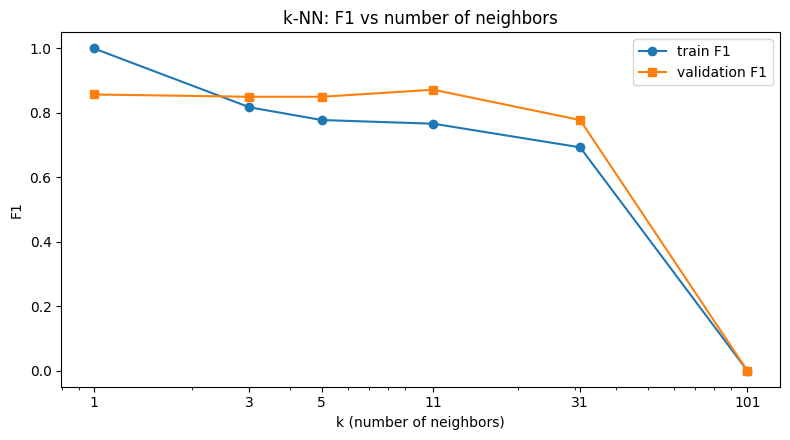

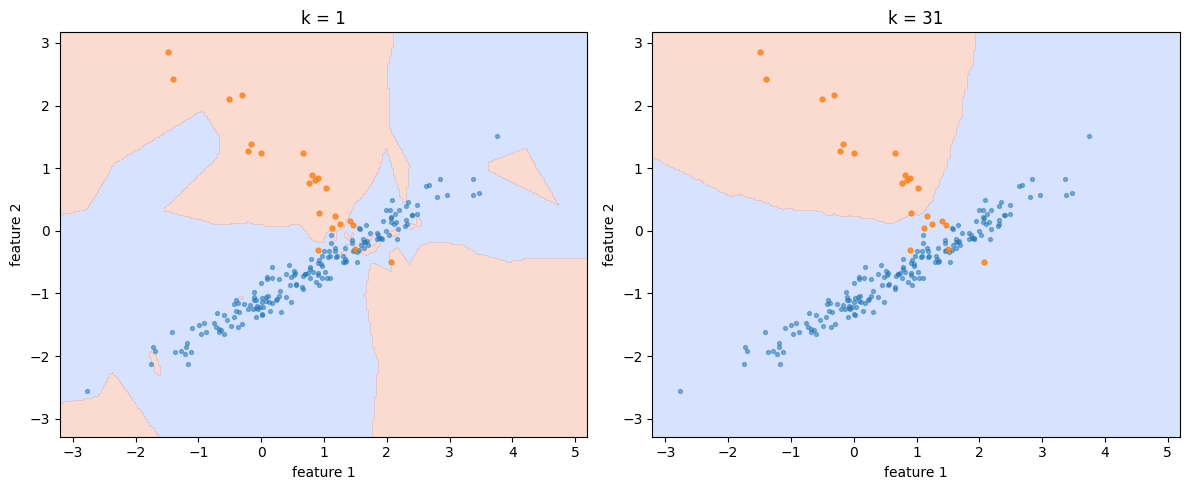

In [9]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(df_knn["k"], df_knn["train_f1"], "o-", label="train F1")
ax.plot(df_knn["k"], df_knn["val_f1"], "s-", label="validation F1")
ax.set_xscale("log")
ax.set_xticks(ks)
ax.set_xticklabels(ks)
ax.set_xlabel("k (number of neighbors)")
ax.set_ylabel("F1")
ax.set_title("k-NN: F1 vs number of neighbors")
ax.legend()
plt.tight_layout()
plt.show()

def plot_boundary(model, ax, title):
    x0 = np.linspace(X_train[:, 0].min() - 0.5, X_train[:, 0].max() + 0.5, 250)
    x1 = np.linspace(X_train[:, 1].min() - 0.5, X_train[:, 1].max() + 0.5, 250)
    xx0, xx1 = np.meshgrid(x0, x1)
    grid = np.c_[xx0.ravel(), xx1.ravel()]
    z = model.predict(grid).reshape(xx0.shape)
    ax.contourf(xx0, xx1, z, levels=[-0.5, 0.5, 1.5], alpha=0.35, cmap="coolwarm")
    ax.scatter(X_val[y_val == 0, 0], X_val[y_val == 0, 1], s=8, alpha=0.5, label="negative")
    ax.scatter(X_val[y_val == 1, 0], X_val[y_val == 1, 1], s=12, alpha=0.8, label="positive")
    ax.set_xlabel("feature 1")
    ax.set_ylabel("feature 2")
    ax.set_title(title)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
plot_boundary(KNeighborsClassifier(n_neighbors=1).fit(X_train, y_train), axes[0], "k = 1")
plot_boundary(KNeighborsClassifier(n_neighbors=31).fit(X_train, y_train), axes[1], "k = 31")
plt.tight_layout()
plt.show()

**Interpretation (D).** Interpret the boundary plots and the F1 curve: how does k act as a complexity control, and where do you see overfitting and underfitting?

**Your answer:** Як k керує складністю моделі: мале k означає високу складність моделі (висока гнучкість, низький bias, високий variance). Модель реагує на кожну окрему точку, утворюючи рвані розділювальні межі. Велике k означає низьку складність моделі (усереднення по великій області, високий bias, низький variance). Межа стає більш гладкою або модель взагалі починає ігнорувати рідкісний клас. Де спостерігається перенавчання: при $k = 1$: на тренувальній вибірці маємо ідеальні показники (train_acc = 1.0, train_f1} = 1.0). Проте графік межі (k=1) дуже зрізаний, утворює острівці навколо кожної точки та підлаштовується під шум у даних. Це класичне перенавчання. Де спостерігається недонавчання: при k = 31 та k = 101: Зі зростанням k межа стає занадто згладженою. При k = 101 у вікні із 101 сусіда рідкісний позитивний клас (якого всього 10%) майже ніколи не збирає більшості голосів, тому модель взагалі перестає передбачати клас 1 (val_f1 = 0.0). Це недонавчання.

**Decision (B).** Which k would you choose based on validation F1, and what is your reasoning? Would you expect k = 1 to be a good choice for a production model?

**Your answer:**  Яке k обрати та обґрунтування: за валідаційним показником F1 найкращим вибором є k = 11, де val_f1 досягає свого максимуму 0.8718 (val_acc = 0.975). Це значення забезпечує оптимальний баланс між гнучкістю моделі та стійкістю до шуму.   Чи буде k = 1 хорошим вибором для продакшену?
Ні, k = 1 є поганим вибором для реальної системи.
Модель з k = 1 вкрай чутлива до будь-яких шумів і викидів у даних (лабельного шуму flip_y). У продакшені на нових даних вона запам'ятовуватиме шумові точки й робитиме багато хибних передбачень, показуючи низьку якість порівняно зі згладженими моделями (k = 5 чи k = 11).

**Counterfactual (E).** Verify the effect of feature scaling on one k:

In [10]:
scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_val_s = scaler.transform(X_val)

knn_scaled = KNeighborsClassifier(n_neighbors=5).fit(X_train_s, y_train)
knn_raw = KNeighborsClassifier(n_neighbors=5).fit(X_train, y_train)
print("k = 5, raw features:    val accuracy {:.3f}, val F1 {:.3f}".format(
    accuracy_score(y_val, knn_raw.predict(X_val)),
    f1_score(y_val, knn_raw.predict(X_val), zero_division=0)))
print("k = 5, scaled features: val accuracy {:.3f}, val F1 {:.3f}".format(
    accuracy_score(y_val, knn_scaled.predict(X_val_s)),
    f1_score(y_val, knn_scaled.predict(X_val_s), zero_division=0)))

k = 5, raw features:    val accuracy 0.970, val F1 0.850
k = 5, scaled features: val accuracy 0.980, val F1 0.900


What changed after scaling and why? For which family of models (distance-based vs tree-based) does scaling matter more, and how would the decision boundary change if one feature had a much larger range than the other?

**Your answer:**  Що змінилося після масштабування і чому: метрики на валідації покращилися: Accuracy зросла з 0.970 до 0.980, а F1-score з виріс з 0.850 до 0.900. Чому так сталося: k-NN використовує евклідову відстань для пошуку найближчих сусідів. Якщо одна ознака має більший розмах чи варіацію, ніж інша, вона починає непропорційно сильніше впливати на результат обчислення відстані. StandardScaler привів обидві ознаки до єдиного масштабу (середнє = 0, стандартне відхилення = 1), тому алгоритм почав враховувати вклад обох ознак однаково та рівноправно.
Для яких моделей масштабування є важливішим: для моделей на основі відстаней (distance-based): масштабування є критично важливим. Сюди належать k-NN, SVM (з RBF/лінійними ядрами), K-Means, а також градієнтні методи (наприклад, логістична регресія чи нейромережі). Для моделей на основі дерев (tree-based): масштабування не має жодного значення. Дерева прийняття рішень (Decision Trees, Random Forest, XGBoost) роблять спліти (поділи) за допомогою умов вида «feature > threshold» для кожної ознаки окремо. Оскільки ця операція інваріантна до монотонних перетворень, масштабування ніяк не змінює структуру дерев чи якість їхньої роботи.
Як змінилася б межа прийняття рішень, якби одна ознака мала значно більший діапазон, ніж інша: якби одна ознака мала, наприклад, діапазон від 0 до 1000, а інша — від 0 до 1, то евклідова відстань визначалася б майже виключно першою ознакою. Зміна межі: межа прийняття рішень витягнулася б уздовж осі другої (дрібної) ознаки і стала б практично паралельною до цієї осі. Алгоритм фактично перестав би реагувати на зміни другої ознаки, перетворивши 2D-задачу на 1D-задачу.

## Takeaways

- With a 10% prevalence, accuracy is dominated by the majority class; report precision, recall, specificity, and F1 together.
- The decision threshold is a business parameter: with asymmetric costs, pick the operating point on the precision–recall trade-off, not the default 0.5.
- ROC is prevalence-insensitive; PR is not. Match the curve (and the test set) to the deployment population.
- k-NN complexity is controlled by k; scaling changes distances, so it changes the model.